# 1. Import thư viện và đọc dữ liệu

Trong phần này, chúng ta sử dụng tập Train đã được làm sạch và chia theo hostname.

Tập Train được sử dụng để khám phá dữ liệu và tìm hiểu sự khác biệt giữa hai nhóm URL phishing và legitimate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Xác định thư mục gốc của project
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "processed" / "train.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Đường dẫn dữ liệu
DATA_PATH = PROJECT_DIR / "data" / "processed" / "train.csv"

# Thư mục lưu kết quả
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
REPORTS_DIR = PROJECT_DIR / "reports"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Đọc dữ liệu
df = pd.read_csv(DATA_PATH)

print("Đọc dữ liệu thành công!")
print("Số lượng URL:", len(df))
print("Số lượng hostname:", df["hostname"].nunique())

df.head()

Đọc dữ liệu thành công!
Số lượng URL: 315125
Số lượng hostname: 116524


,url,type,normalized_url,hostname,has_hostname
0,https://www.youtube.com,legitimate,https://www.youtube.com,www.youtube.com,True
1,https://www.facebook.com,legitimate,https://www.facebook.com,www.facebook.com,True
2,https://www.wikipedia.org,legitimate,https://www.wikipedia.org,www.wikipedia.org,True
3,https://www.reddit.com,legitimate,https://www.reddit.com,www.reddit.com,True
4,https://www.yahoo.com,legitimate,https://www.yahoo.com,www.yahoo.com,True


# 2. Tổng quan dữ liệu

Kiểm tra kích thước dataset, kiểu dữ liệu, giá trị thiếu và phân bố nhãn.

In [2]:
print("Kích thước dataset:", df.shape)

print("\nThông tin các cột:")
df.info()

print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum())

print("\nPhân bố nhãn:")
print(df["type"].value_counts())

print("\nTỷ lệ phần trăm:")
print(
    df["type"].value_counts(normalize=True).mul(100).round(2)
)

Kích thước dataset: (315125, 5)

Thông tin các cột:
<class 'pandas.DataFrame'>
RangeIndex: 315125 entries, 0 to 315124
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   url             315125 non-null  str  
 1   type            315125 non-null  str  
 2   normalized_url  315125 non-null  str  
 3   hostname        315125 non-null  str  
 4   has_hostname    315125 non-null  bool 
dtypes: bool(1), str(4)
memory usage: 54.5 MB

Số lượng giá trị thiếu:
url               0
type              0
normalized_url    0
hostname          0
has_hostname      0
dtype: int64

Phân bố nhãn:
type
legitimate    242019
phishing       73106
Name: count, dtype: int64

Tỷ lệ phần trăm:
type
legitimate    76.8
phishing      23.2
Name: proportion, dtype: float64


Nhận xét :Dữ liệu Train có 315.125 URL, gồm 5 thuộc tính, không có giá trị thiếu. Tỷ lệ hai nhãn lần lượt là 76,8% legitimate và 23,2% phishing.

# 3. Phân bố nhãn

Khảo sát số lượng URL thuộc hai nhóm legitimate và phishing.

Mục tiêu là đánh giá mức độ cân bằng của dataset trước khi huấn luyện mô hình.

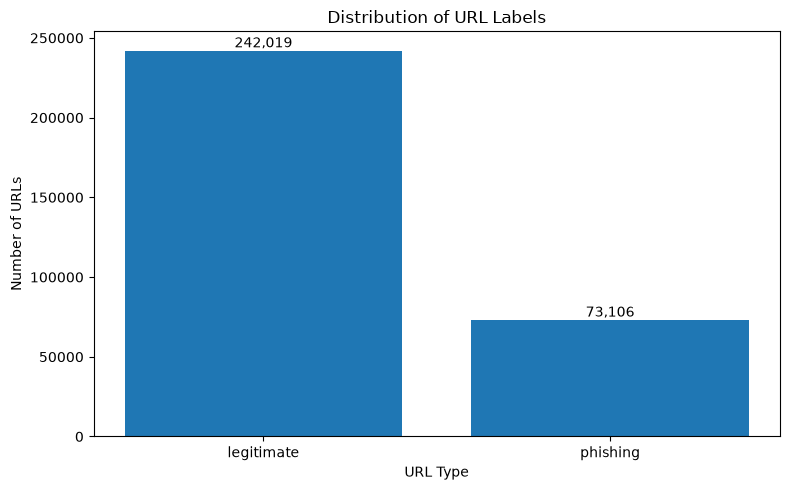

In [3]:
label_counts = df["type"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    label_counts.index,
    label_counts.values
)

plt.title("Distribution of URL Labels")
plt.xlabel("URL Type")
plt.ylabel("Number of URLs")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "label_distribution.png",
    dpi=300
)

plt.show()

Nhận xét biểu đồ
- Legitimate chiếm phần lớn dataset (76,8%).
- Phishing chiếm 23,2%.
- Dữ liệu bị mất cân bằng nhãn, nhưng chưa đến mức quá nghiêm trọng.
- Khi huấn luyện, cần chú ý các chỉ số Precision, Recall, F1-score, đặc biệt là Recall của lớp Phishing. Không nên chỉ dựa vào Accuracy.

# 4. Khám phá đặc trưng URL

Tạo các đặc trưng từ URL và hostname để khảo sát sự khác biệt giữa phishing và legitimate.

Các đặc trưng được khảo sát gồm:

- Độ dài URL.
- Độ dài hostname.
- Số lượng dấu chấm.
- Số lượng dấu gạch ngang.
- Số lượng chữ số.
- Số lượng ký tự @.
- Số lượng dấu gạch chéo.
- Số lượng dấu hỏi.
- Số lượng dấu bằng.
- URL có sử dụng HTTPS hay không.

In [4]:
# Tạo bản sao để không thay đổi dữ liệu ban đầu
eda_df = df.copy()

# Độ dài URL
eda_df["url_length"] = (
    eda_df["normalized_url"].str.len()
)

# Độ dài hostname
eda_df["hostname_length"] = (
    eda_df["hostname"].str.len()
)

# Số lượng dấu chấm
eda_df["dot_count"] = (
    eda_df["normalized_url"].str.count(r"\.")
)

# Số lượng dấu gạch ngang
eda_df["hyphen_count"] = (
    eda_df["normalized_url"].str.count("-")
)

# Số lượng chữ số
eda_df["digit_count"] = (
    eda_df["normalized_url"].str.count(r"\d")
)

# Số lượng ký tự @
eda_df["at_count"] = (
    eda_df["normalized_url"].str.count("@")
)

# Số lượng dấu /
eda_df["slash_count"] = (
    eda_df["normalized_url"].str.count("/")
)

# Số lượng dấu ?
eda_df["question_count"] = (
    eda_df["normalized_url"].str.count(r"\?")
)

# Số lượng dấu =
eda_df["equal_count"] = (
    eda_df["normalized_url"].str.count("=")
)

# URL có sử dụng HTTPS
eda_df["has_https"] = (
    eda_df["normalized_url"]
    .str.lower()
    .str.startswith("https://")
    .astype(int)
)

print("Đã tạo các đặc trưng khảo sát!")

eda_df.head()

Đã tạo các đặc trưng khảo sát!


,url,type,normalized_url,hostname,has_hostname,url_length,hostname_length,dot_count,hyphen_count,digit_count,at_count,slash_count,question_count,equal_count,has_https
0,https://www.youtube.com,legitimate,https://www.youtube.com,www.youtube.com,True,23,15,2,0,0,0,2,0,0,1
1,https://www.facebook.com,legitimate,https://www.facebook.com,www.facebook.com,True,24,16,2,0,0,0,2,0,0,1
2,https://www.wikipedia.org,legitimate,https://www.wikipedia.org,www.wikipedia.org,True,25,17,2,0,0,0,2,0,0,1
3,https://www.reddit.com,legitimate,https://www.reddit.com,www.reddit.com,True,22,14,2,0,0,0,2,0,0,1
4,https://www.yahoo.com,legitimate,https://www.yahoo.com,www.yahoo.com,True,21,13,2,0,0,0,2,0,0,1


https://www.youtube.com
- Độ dài URL: 23 ký tự.
- Hostname: www.youtube.com.
- Có HTTPS nên has_https = 1.
- Có 2 dấu / trong phần https://.
Khớp

# 5. Thống kê đặc trưng theo nhãn

So sánh giá trị trung bình, trung vị và độ lệch chuẩn của các đặc trưng giữa hai nhóm URL.

Qua đó xác định những đặc trưng có sự khác biệt đáng chú ý.

In [5]:
features = [
    "url_length",
    "hostname_length",
    "dot_count",
    "hyphen_count",
    "digit_count",
    "at_count",
    "slash_count",
    "question_count",
    "equal_count",
    "has_https"
]

statistics = eda_df.groupby("type")[features].agg(
    ["mean", "median", "std"]
)

display(statistics.round(2))

# Lưu kết quả thống kê
statistics.to_csv(
    REPORTS_DIR / "feature_statistics.csv"
)

url_length               hostname_length              dot_count  \
                 mean median    std            mean median   std      mean   
type                                                                         
legitimate      57.73   52.0  25.07           19.43   19.0  5.74      2.63   
phishing        66.82   50.0  64.94           18.14   17.0  8.90      2.52   

                        hyphen_count  ... slash_count question_count         \
           median   std         mean  ...         std           mean median   
type                                  ...                                     
legitimate    3.0  0.76         1.42  ...        1.36           0.13    0.0   
phishing      2.0  1.94         0.57  ...        2.04           0.21    0.0   

                 equal_count              has_https               
             std        mean median   std      mean median   std  
type                                                              
legitimate  0.35        0.21    0.0  0.73      1.00    1.0  0.01  
phishing    0.48        0.42    0.0  1.34      0.05    0.0  0.22  

[2 rows x 30 columns]

Nhận xét:
url_length: URL phishing có độ dài trung bình lớn hơn.
question_count, equal_count: URL phishing có nhiều ký tự truy vấn hơn.

has_https: khoảng 100% URL legitimate có HTTPS, trong khi phishing chỉ khoảng 5% theo dữ liệu này.

hostname_length: hai nhóm không chênh lệch quá lớn.

# 6. Phân tích độ dài URL và hostname

So sánh phân bố độ dài URL và hostname giữa phishing và legitimate.

Các giá trị cực lớn được giới hạn trên biểu đồ để dễ quan sát.
Việc giới hạn chỉ phục vụ hiển thị, không thay đổi dữ liệu.

độ dài url

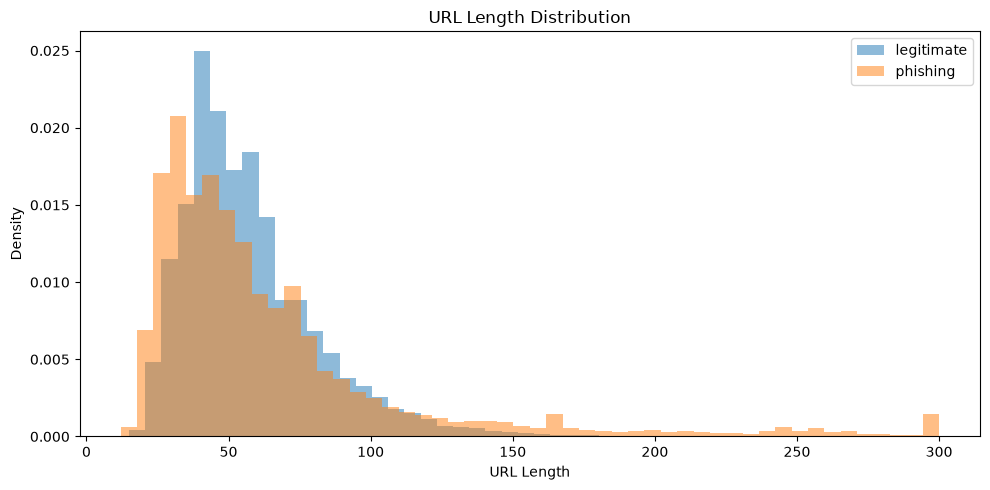

url_length                                                \
                count   mean    std   min   25%   50%   75%     max   
type                                                                  
legitimate   242019.0  57.73  25.07  15.0  41.0  52.0  68.0   651.0   
phishing      73106.0  66.82  64.94  12.0  35.0  50.0  74.0  2314.0   

           hostname_length                                             
                     count   mean   std  min   25%   50%   75%    max  
type                                                                   
legitimate        242019.0  19.43  5.74  5.0  15.0  19.0  22.0   75.0  
phishing           73106.0  18.14  8.90  1.0  13.0  17.0  21.0  240.0

In [ ]:

plt.figure(figsize=(10, 5))

for label in ["legitimate", "phishing"]:

    values = eda_df.loc[
        eda_df["type"] == label,
        "url_length"
    ]

    plt.hist(
        values.clip(upper=300),
        bins=50,
        alpha=0.5,
        label=label,
         density=True
    )

plt.title("URL Length Distribution")
plt.xlabel("URL Length")
plt.ylabel("Number of URLs")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "url_length_distribution.png",
    dpi=300
)

plt.show()
eda_df.groupby("type")[
    ["url_length",]
].describe().round(2)

Nhận xét:
- URL phishing có độ dài trung bình 66,82 ký tự, cao hơn legitimate (57,73 ký tự).
- Tuy nhiên, trung vị của phishing là 50, thấp hơn legitimate là 52.
- 50% URL legitimate nằm trong khoảng 41–68 ký tự, trong khi phishing nằm trong khoảng 35–74 ký tự.
- Độ lệch chuẩn của phishing (64,94) lớn hơn đáng kể so với legitimate (25,07), cho thấy độ dài URL phishing phân tán rộng hơn.
- URL phishing có giá trị tối đa 2314 ký tự, lớn hơn nhiều so với legitimate (651 ký tự).
Kết luận biểu đồ 1:

URL phishing có xu hướng biến động về độ dài lớn hơn URL legitimate. Mặc dù độ dài trung bình cao hơn, hai nhóm vẫn có sự chồng lấn đáng kể ở vùng trung tâm. Do đó, url_length có thể là đặc trưng hữu ích nhưng không đủ để phân loại độc lập.

Độ dài hostname

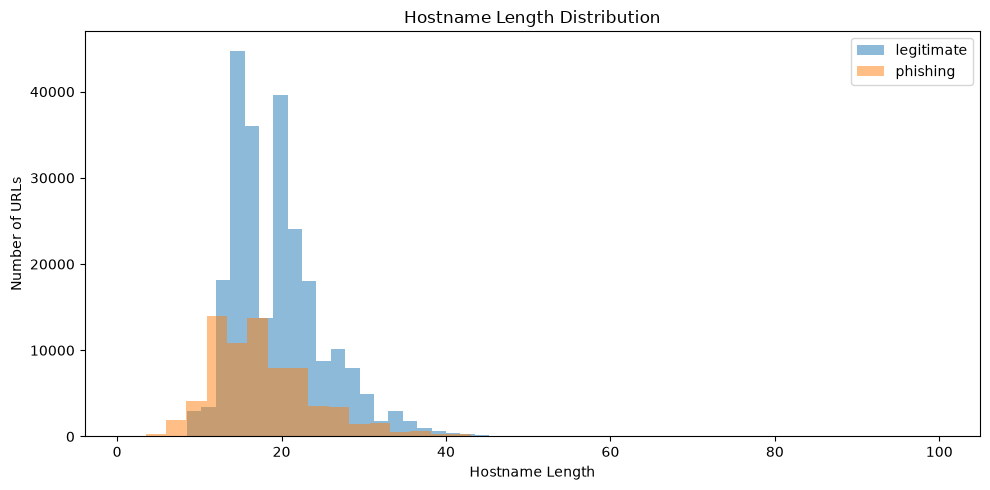

hostname_length                                           
                     count   mean   std  min   25%   50%   75%    max
type                                                                 
legitimate        242019.0  19.43  5.74  5.0  15.0  19.0  22.0   75.0
phishing           73106.0  18.14  8.90  1.0  13.0  17.0  21.0  240.0

In [17]:

plt.figure(figsize=(10, 5))

for label in ["legitimate", "phishing"]:

    values = eda_df.loc[
        eda_df["type"] == label,
        "hostname_length"
    ]

    plt.hist(
        values.clip(upper=100),
        bins=40,
        alpha=0.5,
        label=label
    )

plt.title("Hostname Length Distribution")
plt.xlabel("Hostname Length")
plt.ylabel("Number of URLs")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hostname_length_distribution.png",
    dpi=300
)

plt.show()
eda_df.groupby("type")[
    ["hostname_length"]
].describe().round(2)

Nhận xét:
- Hostname legitimate có độ dài trung bình 19,43 ký tự, cao hơn phishing (18,14 ký tự).
- Trung vị của legitimate là 19, trong khi phishing là 17.
- 50% hostname legitimate nằm trong khoảng 15–22 ký tự, còn phishing nằm trong khoảng 13–21 ký tự.
- Độ lệch chuẩn của phishing (8,90) lớn hơn legitimate (5,74), cho thấy độ dài hostname phishing biến động nhiều hơn.
- Giá trị tối đa của phishing là 240 ký tự, cao hơn đáng kể so với legitimate (75 ký tự).
Kết luận biểu đồ 2:

Độ dài hostname của hai nhóm tương đối gần nhau ở vùng trung tâm. Tuy nhiên, hostname phishing có độ phân tán lớn hơn và xuất hiện một số trường hợp có độ dài bất thường. Vì vậy, hostname_length có thể hỗ trợ nhận diện phishing nhưng khả năng phân biệt riêng lẻ còn hạn chế.

# kết luận node 6
Qua phân tích hai đặc trưng url_length và hostname_length, nhóm nhận thấy URL phishing có độ dài tổng thể biến động lớn hơn URL legitimate. Trong khi đó, độ dài hostname giữa hai nhóm khá tương đồng, mặc dù nhóm phishing có độ phân tán lớn hơn. Điều này cho thấy các đặc trưng về độ dài URL có thể cung cấp thông tin hữu ích trong việc nhận diện website phishing, nhưng không thể sử dụng riêng lẻ để đưa ra kết luận chính xác. Vì vậy, cần kết hợp với các đặc trưng khác để nâng cao hiệu quả phân loại của mô hình.

# 7. Phân tích ký tự đặc biệt

Khảo sát số lượng ký tự đặc biệt xuất hiện trong URL của hai nhóm.

Các ký tự được khảo sát gồm:

- Dấu chấm.
- Dấu gạch ngang.
- Chữ số.
- Ký tự @.
- Dấu gạch chéo.
- Dấu hỏi.

Sử dụng biểu đồ Boxplot để quan sát trung vị, độ phân tán và các giá trị ngoại lệ.

<Figure size 800x500 with 0 Axes>

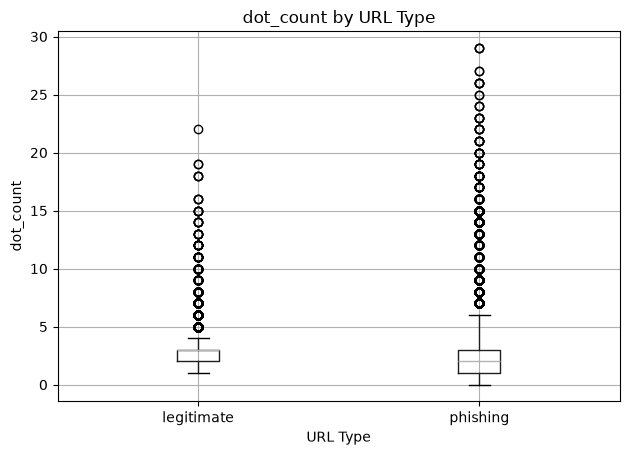

<Figure size 800x500 with 0 Axes>

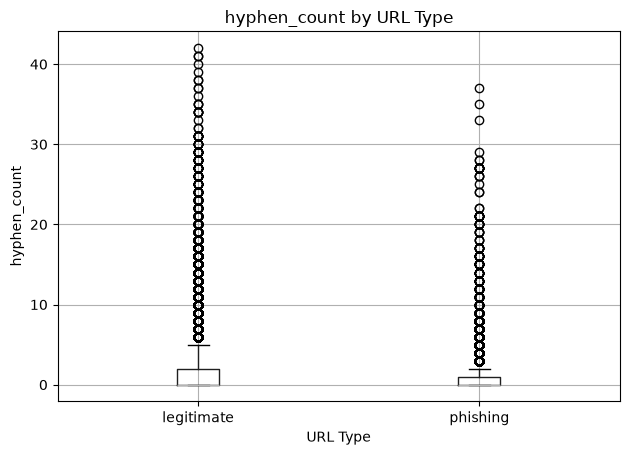

<Figure size 800x500 with 0 Axes>

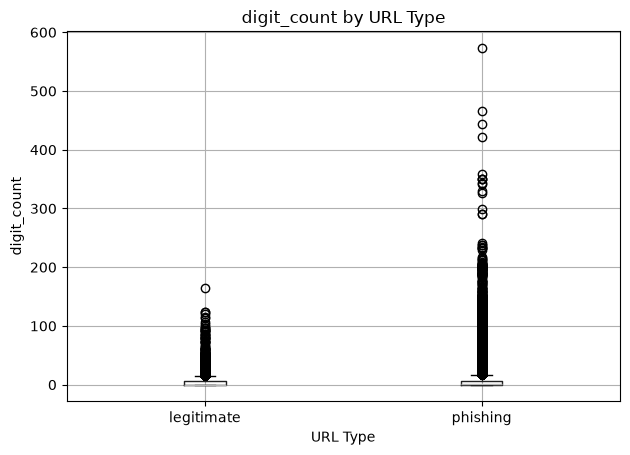

<Figure size 800x500 with 0 Axes>

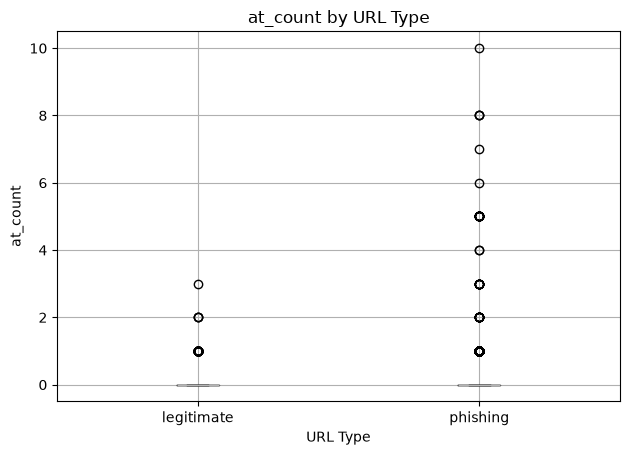

<Figure size 800x500 with 0 Axes>

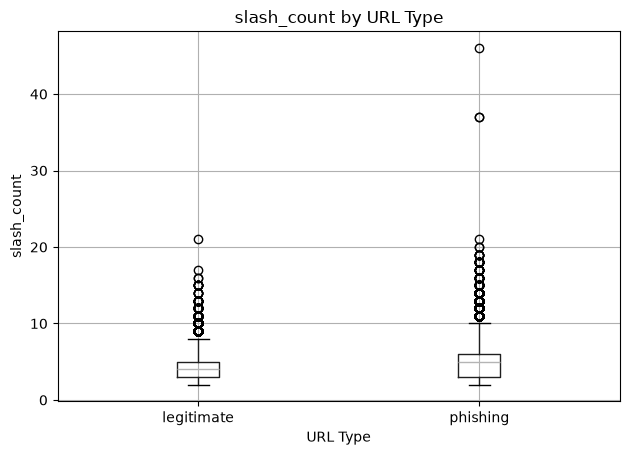

<Figure size 800x500 with 0 Axes>

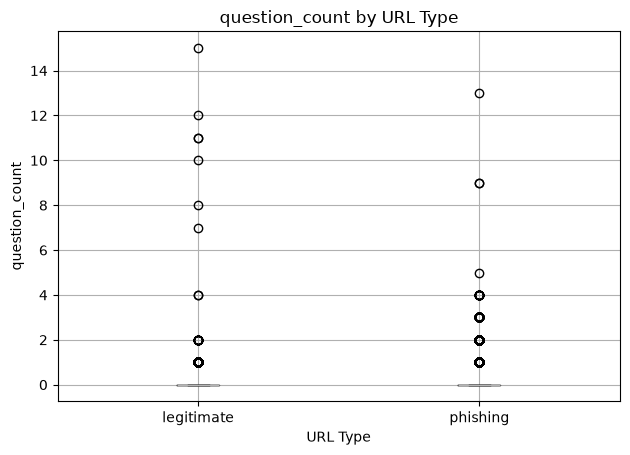

digit_count                        at_count                       \
                  mean median    std min  max     mean median   std min max   
type                                                                          
legitimate        3.23    0.0   4.78   0  165     0.00    0.0  0.02   0   3   
phishing          7.47    1.0  17.26   0  573     0.03    0.0  0.20   0  10   

           slash_count                       
                  mean median   std min max  
type                                         
legitimate        4.28    4.0  1.36   2  21  
phishing          4.93    5.0  2.04   2  46

dot_count                      hyphen_count                       \
                mean median   std min max         mean median   std min max   
type                                                                          
legitimate      2.63    3.0  0.76   1  22         1.42    0.0  2.75   0  42   
phishing        2.52    2.0  1.94   0  29         0.57    0.0  1.36   0  37   

            ... question_count                      equal_count               \
            ...           mean median   std min max        mean median   std   
type        ...                                                                
legitimate  ...           0.13    0.0  0.35   0  15        0.21    0.0  0.73   
phishing    ...           0.21    0.0  0.48   0  13        0.42    0.0  1.34   

                    
           min max  
type                
legitimate   0  34  
phishing     0  27  

[2 rows x 35 columns]

In [20]:
compare_features = [
    "dot_count",
    "hyphen_count",
    "digit_count",
    "at_count",
    "slash_count",
    "question_count"
]

for feature in compare_features:

    plt.figure(figsize=(8, 5))

    eda_df.boxplot(
        column=feature,
        by="type"
    )

    plt.title(f"{feature} by URL Type")
    plt.suptitle("")
    plt.xlabel("URL Type")
    plt.ylabel(feature)

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"{feature}_comparison.png",
        dpi=300
    )

    plt.show()
    
# NODE 7: Thống kê các đặc trưng ký tự theo nhãn

features = [
    "dot_count",
    "hyphen_count",
    "digit_count",
    "at_count",
    "slash_count",
    "question_count",
    "equal_count"
]

node7_stats = eda_df.groupby("type")[features].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)


missing_features = [
    "digit_count",
    "at_count",
    "slash_count"
]

display(
    eda_df.groupby("type")[missing_features]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

display(node7_stats)


Qua phân tích các đặc trưng ký tự trong URL, nhóm nhận thấy một số đặc trưng có sự khác biệt giữa hai nhóm legitimate và phishing. Cụ thể, nhóm phishing có số chữ số, dấu gạch chéo, dấu hỏi và dấu bằng trung bình cao hơn. Đặc biệt, số lượng chữ số có sự chênh lệch đáng chú ý giữa hai nhóm. Ngược lại, số dấu chấm và dấu gạch ngang không cho thấy xu hướng tăng ở nhóm phishing. Ngoài ra, nhóm phishing thường có độ phân tán lớn hơn ở nhiều đặc trưng. Những kết quả này cho thấy các đặc trưng ký tự có thể cung cấp thông tin hữu ích cho việc nhận diện URL phishing, tuy nhiên cần kết hợp nhiều đặc trưng để nâng cao hiệu quả phân loại.

# 8. Kiểm tra dữ liệu trùng lặp

Kiểm tra URL trùng lặp và hostname xuất hiện với nhiều nhãn khác nhau.

Việc này giúp đánh giá chất lượng dữ liệu và nhận diện những trường hợp cần phân tích thêm.

In [21]:
# Kiểm tra URL trùng lặp
duplicate_count = (
    eda_df["normalized_url"].duplicated().sum()
)

print("Số URL trùng lặp:", duplicate_count)

# Kiểm tra hostname có nhiều nhãn
hostname_label_count = (
    eda_df.groupby("hostname")["type"].nunique()
)

conflicting_hosts = hostname_label_count[
    hostname_label_count > 1
]

print(
    "Số hostname xuất hiện với nhiều nhãn:",
    len(conflicting_hosts)
)

# Xem một số hostname có nhiều nhãn
conflicting_host_names = conflicting_hosts.index[:20]

display(
    eda_df[
        eda_df["hostname"].isin(conflicting_host_names)
    ][["normalized_url", "hostname", "type"]]
)

Số URL trùng lặp: 0
Số hostname xuất hiện với nhiều nhãn: 38


,normalized_url,hostname,type
1,https://www.facebook.com,www.facebook.com,legitimate
16,https://www.google.de,www.google.de,legitimate
17,https://www.google.co.uk,www.google.co.uk,legitimate
19,https://www.google.ru,www.google.ru,legitimate
29,https://www.google.com.mx,www.google.com.mx,legitimate
...,...,...,...
312944,https://www.dropbox.com/l/scl/AACi78NknITPKsO7...,www.dropbox.com,phishing
313206,https://www.goo.gl/my73VS,www.goo.gl,phishing
313342,https://www.goo.gl/MKkRKL,www.goo.gl,phishing
314540,https://www.google.ro/url?sa=t&rct=j&q=&esrc=s...,www.google.ro,phishing


Qua kiểm tra dữ liệu, nhóm không phát hiện URL trùng lặp trong tập Train. Tuy nhiên, có 38 hostname xuất hiện với nhiều nhãn khác nhau, bao gồm cả legitimate và phishing. Nguyên nhân có thể xuất phát từ việc cùng một tên miền chứa nhiều đường dẫn với nội dung hoặc mục đích khác nhau, hoặc do sự khác biệt trong nguồn thu thập và quá trình gán nhãn. Điều này cho thấy hostname đơn lẻ không đủ để xác định một URL có phải phishing hay không. Vì vậy, mô hình cần xem xét thêm các đặc trưng của toàn bộ URL thay vì chỉ dựa vào hostname.